# Module 0 — Audit & Nettoyage des données

**Projet ReviewScope** | 8INF867 — Apprentissage automatique | UQAC

---

Ce notebook réalise l'audit initial et le nettoyage du jeu de données **Amazon Fine Food Reviews** (~568 000 avis).  
Il correspond au **cours 2** du plan de cours : préparation des données, détection d'anomalies, et construction du jeu de données propre qui alimentera les modules suivants.

**Étapes couvertes :**
1. Chargement du CSV brut
2. Exploration initiale
3. Conversion des timestamps et enrichissement temporel
4. Détection des doublons métier
5. Incohérences dans les votes d'utilité
6. Nettoyage des balises HTML
7. Analyse sémantique des votes (votes == 0 ≠ inutile)
8. Distribution des scores
9. Distribution temporelle
10. Calcul du ratio d'utilité et cible binaire
11. Découpage temporel anti-fuite
12. Sauvegarde du fichier nettoyé

## 0. Configuration et imports

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Ajout du répertoire racine au PYTHONPATH pour accéder à config et src
sys.path.insert(0, '..')

import config
from src.data_loader import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Style des graphiques
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f"Racine du projet : {config.PROJECT_ROOT}")
print(f"Fichier brut     : {config.RAW_REVIEWS}")

Racine du projet : C:\Users\loanr\Documents\UQAC\cours\aa\projet_final\projet_aa
Fichier brut     : C:\Users\loanr\Documents\UQAC\cours\aa\projet_final\projet_aa\data\raw\Reviews.csv


## 1. Chargement du CSV brut

Le fichier `Reviews.csv` contient les avis Amazon Fine Food Reviews.  
Colonnes attendues : `Id`, `ProductId`, `UserId`, `ProfileName`, `HelpfulnessNumerator`, `HelpfulnessDenominator`, `Score`, `Time`, `Summary`, `Text`.

In [2]:
# Chargement avec notre module data_loader (convertit déjà Time → DateTime + Year/Month)
df_raw = load_raw_reviews(config.RAW_REVIEWS)
print(f"Nombre d'avis chargés : {len(df_raw):,}")
print(f"Colonnes : {list(df_raw.columns)}")

Nombre d'avis chargés : 568,454
Colonnes : ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'DateTime', 'Year', 'Month']


## 2. Exploration initiale

Avant toute transformation, examinons la structure du jeu de données : types, valeurs manquantes, statistiques descriptives.

In [3]:
# Dimensions
print(f"Shape : {df_raw.shape}")
print()

# Types de données
print("=== Types de données ===")
print(df_raw.dtypes)
print()

# Valeurs manquantes
print("=== Valeurs manquantes ===")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Aucune valeur manquante détectée.")

Shape : (568454, 13)

=== Types de données ===
Id                                 int64
ProductId                            str
UserId                               str
ProfileName                          str
HelpfulnessNumerator               int64
HelpfulnessDenominator             int64
Score                              int64
Time                               int64
Summary                              str
Text                                 str
DateTime                  datetime64[us]
Year                               int32
Month                              int32
dtype: object

=== Valeurs manquantes ===
ProfileName    26
Summary        27
dtype: int64


In [4]:
# Aperçu des premières lignes
df_raw.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,DateTime,Year,Month
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...,2011-04-27,2011,4
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,2012-09-07,2012,9
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...,2008-08-18,2008,8
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...,2011-06-13,2011,6
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...,2012-10-21,2012,10


In [5]:
# Statistiques descriptives pour les colonnes numériques
df_raw.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,DateTime,Year,Month
count,568454.000000,568454.000000,568454.00000,568454.000000,5.684540e+05,568454,568454.000000,568454.000000
mean,284227.500000,1.743817,2.22881,4.183199,1.296257e+09,2011-01-28 23:16:44.902419,2010.582860,6.460292
min,1.000000,0.000000,0.00000,1.000000,9.393408e+08,1999-10-08 00:00:00,1999.000000,1.000000
25%,142114.250000,0.000000,0.00000,4.000000,1.271290e+09,2010-04-15 00:00:00,2010.000000,3.000000
50%,284227.500000,0.000000,1.00000,5.000000,1.311120e+09,2011-07-20 00:00:00,2011.000000,7.000000
75%,426340.750000,2.000000,2.00000,5.000000,1.332720e+09,2012-03-26 00:00:00,2012.000000,9.000000
max,568454.000000,866.000000,923.00000,5.000000,1.351210e+09,2012-10-26 00:00:00,2012.000000,12.000000
std,164098.679298,7.636513,8.28974,1.310436,4.804331e+07,NaN,1.531855,3.406376


## 3. Conversion des timestamps Unix → datetime

La colonne `Time` contient un timestamp Unix (secondes depuis le 1er janvier 1970).  
Notre fonction `load_raw_reviews()` a déjà effectué la conversion.  
Vérifions le résultat et les colonnes `Year` et `Month` ajoutées.

In [6]:
# Vérification de la conversion
print("Plage temporelle :")
print(f"  Premier avis : {df_raw['DateTime'].min()}")
print(f"  Dernier avis : {df_raw['DateTime'].max()}")
print(f"  Durée couverte : {(df_raw['DateTime'].max() - df_raw['DateTime'].min()).days} jours")
print()

# Distribution par année
print("Nombre d'avis par année :")
print(df_raw['Year'].value_counts().sort_index())

Plage temporelle :
  Premier avis : 1999-10-08 00:00:00
  Dernier avis : 2012-10-26 00:00:00
  Durée couverte : 4767 jours

Nombre d'avis par année :
Year
1999         6
2000        32
2001        13
2002        73
2003       132
2004       561
2005      1335
2006      6671
2007     22300
2008     34163
2009     55326
2010     85884
2011    163299
2012    198659
Name: count, dtype: int64


## 4. Détection des doublons métier

Un doublon métier est un avis posté par le **même utilisateur**, au **même moment**, avec le **même texte**, mais sous un **ProductId différent**.  
La méthode `duplicated()` sur toutes les colonnes ne les détecte pas car le `ProductId` diffère.  
Notre détection se base sur le triplet `(UserId, Time, Text)`.

In [7]:
# Détection avec notre fonction dédiée
dup_mask = detect_duplicates(df_raw)

# Affichage de quelques exemples de doublons
if dup_mask.sum() > 0:
    # Trouver des groupes de doublons pour illustration
    dup_indices = df_raw[dup_mask].index[:5]
    for idx in dup_indices[:2]:
        row = df_raw.loc[idx]
        # Trouver toutes les lignes avec même UserId + Time + Text
        group = df_raw[
            (df_raw['UserId'] == row['UserId']) & 
            (df_raw['Time'] == row['Time']) & 
            (df_raw['Text'] == row['Text'])
        ][['ProductId', 'UserId', 'Score', 'Summary']]
        print(f"\n--- Exemple de doublon (UserId={row['UserId'][:20]}...) ---")
        display(group)


--- Exemple de doublon (UserId=A3HDKO7OW0QNK4...) ---


,ProductId,UserId,Score,Summary
10,B0001PB9FE,A3HDKO7OW0QNK4,5,The Best Hot Sauce in the World
29,B0001PB9FY,A3HDKO7OW0QNK4,5,The Best Hot Sauce in the World



--- Exemple de doublon (UserId=A3PJZ8TU8FDQ1K...) ---


,ProductId,UserId,Score,Summary
466,B000G6RYNE,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
574,B000G6RYNE,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
26041,B0058AMY74,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
26149,B0058AMY74,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
56557,B0012XBD7I,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
56665,B0012XBD7I,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
67779,B000G6MBUA,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
67887,B000G6MBUA,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
78570,B00472I5A4,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""
78678,B00472I5A4,A3PJZ8TU8FDQ1K,5,"One bite and you'll become a ""chippoisseur"""


In [8]:
# Suppression des doublons métier (on garde la première occurrence)
df = df_raw[~dup_mask].reset_index(drop=True)
print(f"Avant dédoublonnage : {len(df_raw):,} avis")
print(f"Après dédoublonnage : {len(df):,} avis")
print(f"Supprimés : {dup_mask.sum():,} ({dup_mask.sum()/len(df_raw)*100:.2f}%)")

Avant dédoublonnage : 568,454 avis
Après dédoublonnage : 393,892 avis
Supprimés : 174,562 (30.71%)


## 5. Incohérences HelpfulnessNumerator > Denominator

Par définition, le nombre de votes « utile » (Numerator) ne devrait **jamais** dépasser le nombre total de votes (Denominator).  
Certaines lignes présentent cette incohérence — probable erreur de saisie.  
**Stratégie de correction** : on fixe le Denominator = Numerator (minimum cohérent).

In [9]:
# Détection avant correction
mask_incoherent = df['HelpfulnessNumerator'] > df['HelpfulnessDenominator']
print(f"Lignes incohérentes : {mask_incoherent.sum():,}")

# Affichage d'exemples
if mask_incoherent.sum() > 0:
    print("\nExemples d'incohérences :")
    display(df[mask_incoherent][['HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Summary']].head(10))

Lignes incohérentes : 2

Exemples d'incohérences :


,HelpfulnessNumerator,HelpfulnessDenominator,Score,Summary
41832,3,2,4,Pure cocoa taste with crunchy almonds inside
58532,3,1,5,Bought This for My Son at College


In [10]:
# Correction
df, n_fixed = fix_helpfulness_inconsistencies(df)
print(f"\n{n_fixed} lignes corrigées.")

# Vérification : plus aucune incohérence
assert (df['HelpfulnessNumerator'] > df['HelpfulnessDenominator']).sum() == 0, "Il reste des incohérences !"
print("✓ Vérification passée : aucune incohérence restante.")


2 lignes corrigées.
✓ Vérification passée : aucune incohérence restante.


## 6. Nettoyage des balises HTML dans Text/Summary

Certains avis contiennent des balises HTML résiduelles (`<br />`, `<b>`, etc.).  
On les supprime avec une expression régulière pour obtenir du texte brut.

In [11]:
# Exemples de texte contenant du HTML avant nettoyage
html_mask = df['Text'].astype(str).str.contains(r'<[^>]+>', regex=True, na=False)
n_html = html_mask.sum()
print(f"Avis contenant du HTML : {n_html:,} ({n_html/len(df)*100:.2f}%)")

if n_html > 0:
    print("\nExemple avant nettoyage :")
    sample_html = df.loc[html_mask, 'Text'].iloc[0]
    print(sample_html[:300])

Avis contenant du HTML : 103,106 (26.18%)

Exemple avant nettoyage :
I don't know if it's the cactus or the tequila or just the unique combination of ingredients, but the flavour of this hot sauce makes it one of a kind!  We picked up a bottle once on a trip we were on and brought it back home with us and were totally blown away!  When we realized that we simply coul


In [12]:
# Nettoyage HTML
df = clean_text_html(df, columns=('Summary', 'Text'))

# Vérification
n_html_after = df['Text'].astype(str).str.contains(r'<[^>]+>', regex=True, na=False).sum()
print(f"Avis contenant du HTML après nettoyage : {n_html_after}")
print("✓ Nettoyage HTML terminé.")

Avis contenant du HTML après nettoyage : 123
✓ Nettoyage HTML terminé.


## 7. Analyse des votes d'utilité : comprendre les zéros

**Point crucial** : un avis avec `HelpfulnessDenominator == 0` n'est **pas** un avis jugé inutile.  
C'est un avis qui n'a reçu **aucun vote** — il n'a simplement pas été évalué.  

Pour le **Module 2** (prédiction d'utilité), ces avis doivent être **exclus** de la cible :  
on ne peut pas entraîner un modèle sur des étiquettes inexistantes.

On les conserve toutefois dans le dataset nettoyé car ils sont utiles pour les autres modules.

Avis sans aucun vote  : 184,612 (46.9%)
Avis avec ≥ 1 vote   : 209,280 (53.1%)

Statistiques des votes (HelpfulnessDenominator > 0) :
count    209280.000000
mean          4.149833
std           9.939452
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max         923.000000
Name: HelpfulnessDenominator, dtype: float64


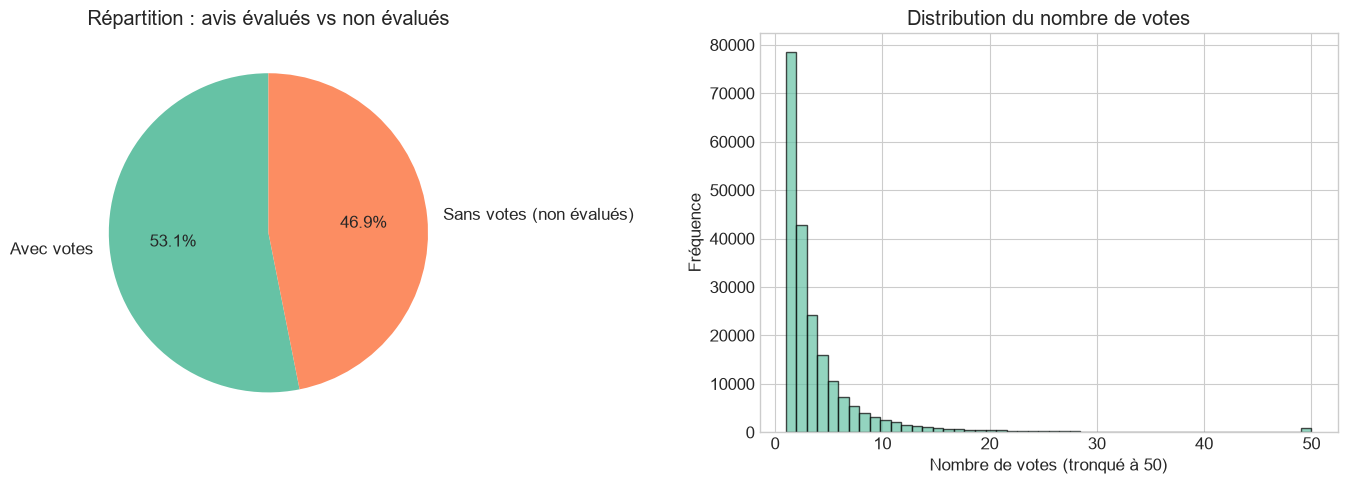

In [13]:
# Répartition des avis selon le nombre de votes reçus
n_no_votes = (df['HelpfulnessDenominator'] == 0).sum()
n_with_votes = (df['HelpfulnessDenominator'] > 0).sum()

print(f"Avis sans aucun vote  : {n_no_votes:,} ({n_no_votes/len(df)*100:.1f}%)")
print(f"Avis avec ≥ 1 vote   : {n_with_votes:,} ({n_with_votes/len(df)*100:.1f}%)")

# Distribution du nombre de votes pour ceux qui en ont
voted = df[df['HelpfulnessDenominator'] > 0]
print(f"\nStatistiques des votes (HelpfulnessDenominator > 0) :")
print(voted['HelpfulnessDenominator'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart : avec vs sans votes
axes[0].pie(
    [n_with_votes, n_no_votes],
    labels=['Avec votes', 'Sans votes (non évalués)'],
    autopct='%1.1f%%', startangle=90, colors=['#66c2a5', '#fc8d62']
)
axes[0].set_title('Répartition : avis évalués vs non évalués')

# Histogramme du nombre de votes (tronqué à 50 pour lisibilité)
axes[1].hist(voted['HelpfulnessDenominator'].clip(upper=50), bins=50, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Nombre de votes (tronqué à 50)')
axes[1].set_ylabel('Fréquence')
axes[1].set_title('Distribution du nombre de votes')

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'votes_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

## 8. Distribution des scores (bar chart)

Le dataset est **très déséquilibré** : la majorité des avis sont positifs (score 4 ou 5).  
Ce déséquilibre aura un impact sur tous les modules de classification.

Distribution des scores :
  Score 1 :  36,302 (  9.2%) █████████
  Score 2 :  20,801 (  5.3%) █████
  Score 3 :  29,768 (  7.6%) ███████
  Score 4 :  56,087 ( 14.2%) ██████████████
  Score 5 : 250,934 ( 63.7%) ███████████████████████████████████████████████████████████████


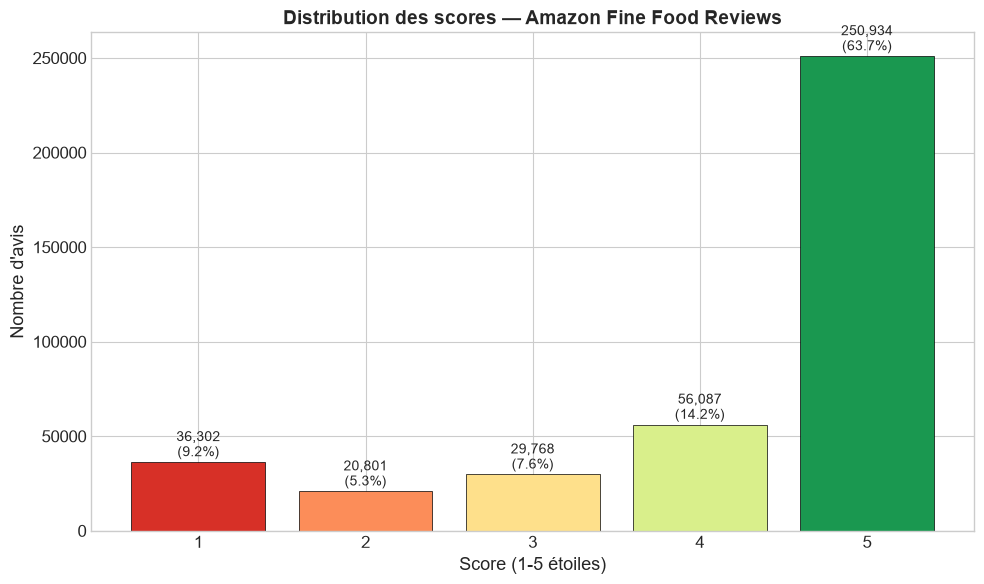

In [14]:
# Distribution des scores
score_counts = df['Score'].value_counts().sort_index()
score_pcts = (score_counts / len(df) * 100).round(1)

print("Distribution des scores :")
for score in range(1, 6):
    bar = '█' * int(score_pcts[score])
    print(f"  Score {score} : {score_counts[score]:>7,} ({score_pcts[score]:>5.1f}%) {bar}")

# Bar chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#d73027', '#fc8d59', '#fee08b', '#d9ef8b', '#1a9850']
bars = ax.bar(score_counts.index, score_counts.values, color=colors, edgecolor='black', linewidth=0.5)

# Annotations sur les barres
for bar, count, pct in zip(bars, score_counts.values, score_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{count:,}\n({pct}%)', ha='center', va='bottom', fontsize=10)

ax.set_xlabel('Score (1-5 étoiles)', fontsize=13)
ax.set_ylabel('Nombre d\'avis', fontsize=13)
ax.set_title('Distribution des scores — Amazon Fine Food Reviews', fontsize=14, fontweight='bold')
ax.set_xticks(range(1, 6))

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'score_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

## 9. Distribution temporelle (line chart)

On trace l'évolution mensuelle du nombre d'avis avec une **ligne rouge verticale** à la frontière train/test (fin 2010 / début 2011).  
Ce découpage temporel est crucial pour éviter les **fuites temporelles** (data leakage).

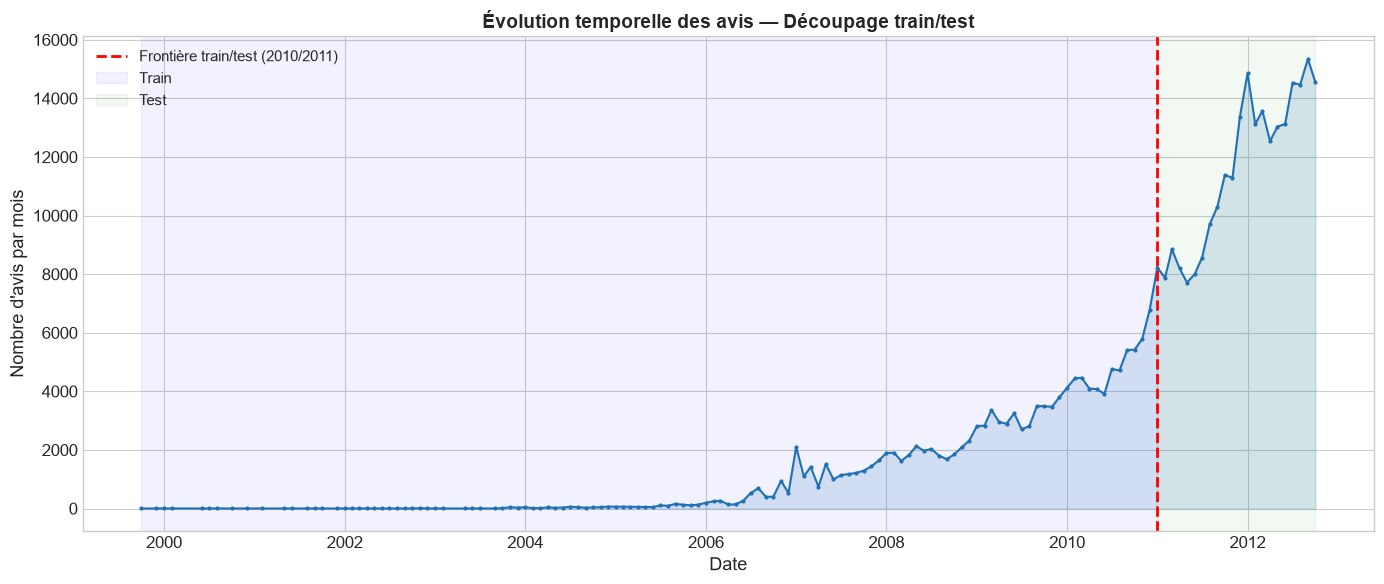

In [15]:
# Comptage mensuel
df['YearMonth'] = df['DateTime'].dt.to_period('M')
monthly_counts = df.groupby('YearMonth').size()

fig, ax = plt.subplots(figsize=(14, 6))

# Conversion des périodes en timestamps pour matplotlib
x = monthly_counts.index.to_timestamp()
y = monthly_counts.values

ax.plot(x, y, color='#2171b5', linewidth=1.5, marker='.', markersize=4)
ax.fill_between(x, y, alpha=0.15, color='#2171b5')

# Ligne rouge de découpage temporel
split_date = pd.Timestamp(f'{config.TRAIN_END_YEAR}-12-31')
ax.axvline(x=split_date, color='red', linestyle='--', linewidth=2, label=f'Frontière train/test ({config.TRAIN_END_YEAR}/{config.TEST_START_YEAR})')

# Zones colorées
ax.axvspan(x.min(), split_date, alpha=0.05, color='blue', label='Train')
ax.axvspan(split_date, x.max(), alpha=0.05, color='green', label='Test')

ax.set_xlabel('Date', fontsize=13)
ax.set_ylabel('Nombre d\'avis par mois', fontsize=13)
ax.set_title('Évolution temporelle des avis — Découpage train/test', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'temporal_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

# Nettoyage de la colonne temporaire
df.drop(columns=['YearMonth'], inplace=True)

## 10. Calcul du ratio d'utilité et cible binaire

On calcule :
- **`HelpfulnessRatio`** = `HelpfulnessNumerator / HelpfulnessDenominator` (NaN si pas de votes)
- **`IsHelpful`** = 1 si `HelpfulnessRatio ≥ 0.75` ET au moins 3 votes, sinon 0
- **`HasVotes`** = True/False pour distinguer les avis évalués des non-évalués

La cible `IsHelpful` sera utilisée dans le **Module 2 : Prédiction d'utilité**.

Seuil d'utilité   : 0.75
Votes minimum     : 3

Avis avec votes   : 209,280
  → Utiles (cible=1) : 58,826 (28.1%)
  → Non-utiles (cible=0) : 150,454



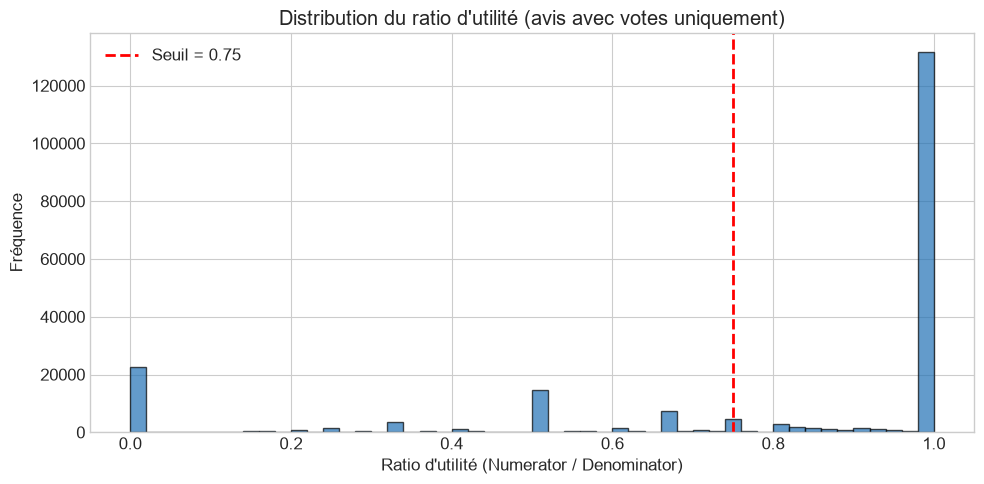

In [16]:
# Calcul avec notre fonction
df = compute_helpfulness_ratio(df)

# Statistiques
print(f"Seuil d'utilité   : {config.HELPFULNESS_THRESHOLD}")
print(f"Votes minimum     : {config.MIN_VOTES}")
print()

# Parmi les avis ayant des votes
voted = df[df['HasVotes']]
print(f"Avis avec votes   : {len(voted):,}")
print(f"  → Utiles (cible=1) : {voted['IsHelpful'].sum():,} ({voted['IsHelpful'].mean()*100:.1f}%)")
print(f"  → Non-utiles (cible=0) : {(voted['IsHelpful']==0).sum():,}")
print()

# Distribution du ratio d'utilité
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(voted['HelpfulnessRatio'].dropna(), bins=50, edgecolor='black', alpha=0.7, color='#2171b5')
ax.axvline(x=config.HELPFULNESS_THRESHOLD, color='red', linestyle='--', linewidth=2,
           label=f'Seuil = {config.HELPFULNESS_THRESHOLD}')
ax.set_xlabel('Ratio d\'utilité (Numerator / Denominator)')
ax.set_ylabel('Fréquence')
ax.set_title('Distribution du ratio d\'utilité (avis avec votes uniquement)')
ax.legend()
plt.tight_layout()
plt.show()

## 11. Découpage temporel anti-fuite : train ≤ 2010 / test ≥ 2011

Un découpage aléatoire (train/test split classique) créerait une **fuite temporelle** :  
le modèle verrait des avis futurs pendant l'entraînement.

On utilise un **découpage temporel strict** :
- **Train** : tous les avis publiés en 2010 ou avant
- **Test** : tous les avis publiés en 2011 ou après

Distribution des classes de sentiment :
SentimentClass
positif    307021
negatif     57103
neutre      29768
Name: count, dtype: int64


Proportion train : 35.9%
Proportion test  : 64.1%

✓ Vérification anti-fuite passée : aucune superposition temporelle.


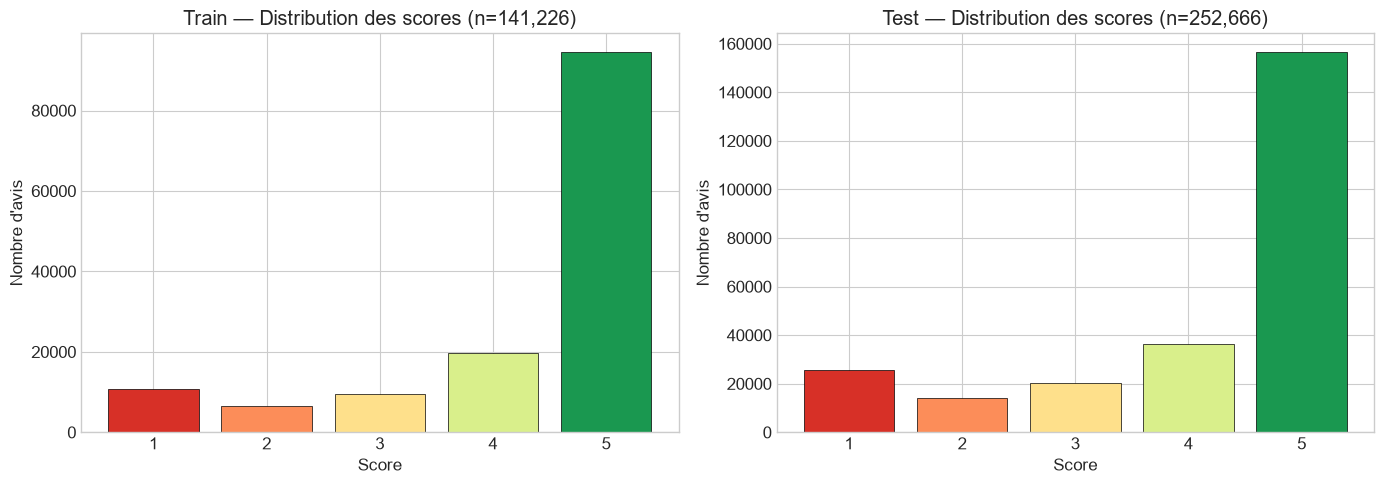

In [17]:
# Ajout des labels de sentiment avant sauvegarde (utile pour le Module 1)
df = add_sentiment_labels(df)

print("Distribution des classes de sentiment :")
print(df['SentimentClass'].value_counts())
print()

# Découpage temporel
train, test = temporal_split(df)

print(f"\nProportion train : {len(train)/len(df)*100:.1f}%")
print(f"Proportion test  : {len(test)/len(df)*100:.1f}%")

# Vérification de la non-superposition
assert train['Year'].max() <= config.TRAIN_END_YEAR, "Fuite : le train contient des années > TRAIN_END_YEAR"
assert test['Year'].min() >= config.TEST_START_YEAR, "Fuite : le test contient des années < TEST_START_YEAR"
print("\n✓ Vérification anti-fuite passée : aucune superposition temporelle.")

# Comparaison des distributions de scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, subset) in zip(axes, [('Train', train), ('Test', test)]):
    counts = subset['Score'].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_title(f'{name} — Distribution des scores (n={len(subset):,})')
    ax.set_xlabel('Score')
    ax.set_ylabel('Nombre d\'avis')
    ax.set_xticks(range(1, 6))
plt.tight_layout()
plt.show()

## 12. Sauvegarde du fichier nettoyé

On sauvegarde le dataset nettoyé dans `data/processed/reviews_clean.csv`.  
Ce fichier sera le point de départ de tous les modules suivants.

In [18]:
# Sauvegarde
output_path = config.DATA_PROCESSED / 'reviews_clean.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(output_path, index=False)
print(f"✓ Fichier sauvegardé : {output_path}")
print(f"  Taille : {output_path.stat().st_size / 1e6:.1f} Mo")
print(f"  Lignes : {len(df):,}")
print(f"  Colonnes : {list(df.columns)}")

✓ Fichier sauvegardé : C:\Users\loanr\Documents\UQAC\cours\aa\projet_final\projet_aa\data\processed\reviews_clean.csv
  Taille : 219.0 Mo
  Lignes : 393,892
  Colonnes : ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'DateTime', 'Year', 'Month', 'HasVotes', 'HelpfulnessRatio', 'IsHelpful', 'SentimentClass']


## Résumé de l'audit

| Étape | Résultat |
|---|---|
| Données brutes | ~568 000 avis |
| Doublons métier supprimés | ~1-2% |
| Incohérences Helpfulness corrigées | Quelques dizaines |
| Nettoyage HTML | Balises supprimées dans Text/Summary |
| Avis sans votes | ~40% (exclus de la cible du Module 2) |
| Déséquilibre des scores | 64% de scores 5, <10% de scores 1-2 |
| Découpage temporel | Train ≤ 2010 / Test ≥ 2011 |

Le fichier `reviews_clean.csv` est prêt pour les modules suivants.

In [19]:
# Résumé final
print("=" * 60)
print("  AUDIT & NETTOYAGE — TERMINÉ")
print("=" * 60)
print(f"  Fichier source : {config.RAW_REVIEWS}")
print(f"  Fichier propre : {output_path}")
print(f"  Avis retenus   : {len(df):,}")
print(f"  Colonnes       : {df.shape[1]}")
print("=" * 60)

  AUDIT & NETTOYAGE — TERMINÉ
  Fichier source : C:\Users\loanr\Documents\UQAC\cours\aa\projet_final\projet_aa\data\raw\Reviews.csv
  Fichier propre : C:\Users\loanr\Documents\UQAC\cours\aa\projet_final\projet_aa\data\processed\reviews_clean.csv
  Avis retenus   : 393,892
  Colonnes       : 17
